In [ ]:
import dataclasses
from collections.abc import Iterator, Mapping
from types import MappingProxyType
from typing import Any, Literal, Optional

import jax
import jax.numpy as jnp
import sklearn
import sklearn.datasets
import pickle
import optax
import torch

import matplotlib.pyplot as plt
from IPython.display import clear_output, display

from ott import datasets
from ott.geometry import costs, pointcloud

from ott.tools import sinkhorn_divergence

import jax
import jax.numpy as jnp
from ott.geometry.geometry import Geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn
import scipy
import numpy as np
import ot 

from typing import Any, Optional

import matplotlib.pyplot as plt
from matplotlib import colors

from ott.geometry import costs, pointcloud
from ott.problems.linear import linear_problem, potentials
from ott.solvers import linear
from ott.tools import progot
import scipy

import pandas as pd
import scanpy as sc
import numpy as np
import sys


In [2]:
# All data / code locations come from config.toml (+ config.local.toml).
from config import PATHS, add_code_dirs
add_code_dirs()
dataset_path = PATHS["imagenet_dir"]

In [3]:
emb_dir = PATHS["embeddings_pkl"]

# Load embeddings from the pickle file
with open(emb_dir, "rb") as f:
    embeddings = pickle.load(f)


# 1. Making it even; remove 1 image
embeddings = embeddings[1:,:]

# 2. Get to a close even number which when divided is non-prime
print(f'num embeddings: {embeddings.shape[0]}')
N = embeddings.shape[0] // 2
q = 640500
k = (N-q)*2

embed_sliced = embeddings[:-k]
n = embed_sliced.shape[0] // 2
print(n)
    
num_samples = embed_sliced.shape[0]

# Shuffle indices
indices = np.random.permutation(num_samples)

# Split into two tensors
X = embed_sliced[indices[:n]]  # First 50%
Y = embed_sliced[indices[n:]]  # Second 50%
print(f"X shape: {X.shape}, Y shape: {Y.shape}")
    
# Ensure it's a NumPy array first (optional but safe)
X_np = np.asarray(X)
Y_np = np.asarray(Y)

num embeddings: 1281166
640500
X shape: (640500, 2048), Y shape: (640500, 2048)


In [4]:
gmm_models_path = PATHS["gmm"]

with open(gmm_models_path, "rb") as f:
    gmm_dict = pickle.load(f)
    
gmm_s = gmm_dict['gmm_s'] 
gmm_t = gmm_dict['gmm_t']

In [5]:
mean_s = gmm_s.means_
mean_t = gmm_t.means_

sigma_s_diag = np.array([np.diag(gmm_s.covariances_[i]) for i in range(len(gmm_s.covariances_))])
sigma_t_diag = np.array([np.diag(gmm_t.covariances_[i]) for i in range(len(gmm_t.covariances_))])

sigma_s = gmm_s.covariances_
sigma_t = gmm_t.covariances_
    
alpha_s = gmm_s.weights_
alpha_t = gmm_t.weights_

max_iter = int(1e6)
stop_thr = 1e-6

In [6]:
from functions import compute_distance_diagonal

C, _, _ = compute_distance_diagonal(mean_s, sigma_s_diag, mean_t, sigma_t_diag, eps=1e-2, batch_size=100)

In [7]:
C_normalized = C / C.max()
omt_w, solver_log = ot.bregman.sinkhorn(alpha_s, alpha_t, C_normalized, 0.01, numItermax=max_iter, stopThr=stop_thr, log=True)
total_cost = np.sum(omt_w * C)
n_iter = solver_log['niter']

885


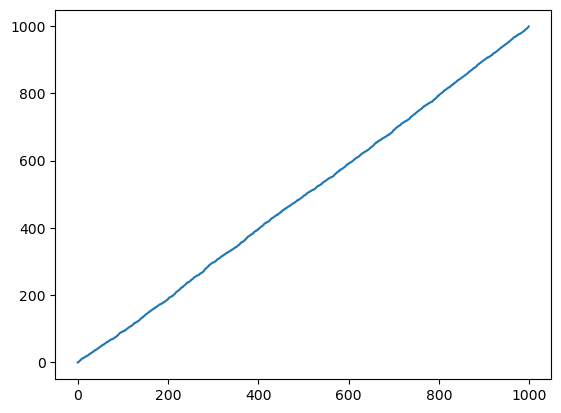

In [8]:
plt.figure()
tmp = np.sort(np.argmax(omt_w, axis=1))
plt.plot(tmp)

print(len(np.unique(tmp)))

In [ ]:
from functions import sample_gmm_kdim, mmd_rbf, points_transport

X_tr = points_transport(X_np, omt_w, gmm_dict)

In [ ]:
euc_cost = torch.norm(X_np - X_tr, dim=1).mean().item() / X_np.shape[1] 
print(f"Average Euclidean cost after transport: {euc_cost}")